# Time Series Basics: Terms, Patterns, and Practical Ideas

This notebook introduces the language and core ideas used when working with time series data. It uses a small **synthetic monthly dataset** so that the underlying trend, seasonal pattern, and random variation are known.

By the end, you should be able to:
- Recognize common time series patterns.
- Explain trend, seasonality, cycles, and noise.
- Understand frequency, lag, autocorrelation, and stationarity.
- Make a time-aware train/test split and evaluate a simple forecast.

**Requirements:** Python, NumPy, pandas, and Matplotlib. The notebook does not require an external dataset.

## 1. What is a time series?

A **time series** is a sequence of observations arranged in time order. Examples include daily temperatures, monthly sales, hourly electricity demand, and yearly population.

A time series usually has two important parts:

- **Time index:** when each observation was recorded.
- **Value:** the measurement recorded at that time.

Unlike a typical unordered table, the order matters. A value from last month may help explain this month, and shuffling the rows can destroy useful information.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')
np.random.seed(7)

# Create four years of monthly observations.
dates = pd.date_range(start='2021-01-01', periods=48, freq='MS')
t = np.arange(len(dates))

# The components are defined separately so we can inspect them later.
trend = 100 + 1.2 * t
seasonal_pattern = np.array([-12, -9, -5, 0, 5, 9, 12, 10, 5, 0, -5, -10])
seasonality = np.tile(seasonal_pattern, 4)
noise = np.random.normal(loc=0, scale=4, size=len(dates))
value = trend + seasonality + noise

df = pd.DataFrame(
    {'value': value, 'trend': trend, 'seasonality': seasonality, 'noise': noise},
    index=dates
)
df.index.name = 'date'
df.head()

,value,trend,seasonality,noise
date,,,,
2021-01-01,94.762103,100.0,-12,6.762103
2021-02-01,90.336251,101.2,-9,-1.863749
2021-03-01,97.531281,102.4,-5,0.131281
2021-04-01,105.230065,103.6,0,1.630065
2021-05-01,106.644308,104.8,5,-3.155692


## 2. Time index, frequency, and regularity

The **frequency** describes how often observations are collected: hourly, daily, weekly, monthly, or yearly, for example. Here, `MS` means **month start**.

A series is **regularly spaced** when observations are recorded at consistent intervals. Real data may be irregular: a sensor might miss readings, or sales might only be recorded on business days. Before analysis, check the time index, sort it, and identify missing timestamps or values.

A missing timestamp is not the same as a timestamp whose value is missing. Both can matter, and the right way to handle them depends on what the data represents.

In [2]:
print('First timestamp:', df.index.min())
print('Last timestamp: ', df.index.max())
print('Number of rows: ', len(df))
print('Inferred frequency:', pd.infer_freq(df.index))
print('Missing values by column:')
print(df.isna().sum())

First timestamp: 2021-01-01 00:00:00
Last timestamp:  2024-12-01 00:00:00
Number of rows:  48
Inferred frequency: MS
Missing values by column:
value          0
trend          0
seasonality    0
noise          0
dtype: int64


## 3. Plotting a time series

A line plot is usually the first useful view. The horizontal axis represents time and the vertical axis represents the measured value. Look for long-term movement, repeating patterns, abrupt changes, gaps, and unusual observations.

An **observation** is one recorded value at one time point. An **outlier** is an observation that differs substantially from the general pattern. An outlier may be an error, a one-off event, or an important real change; do not remove it automatically.

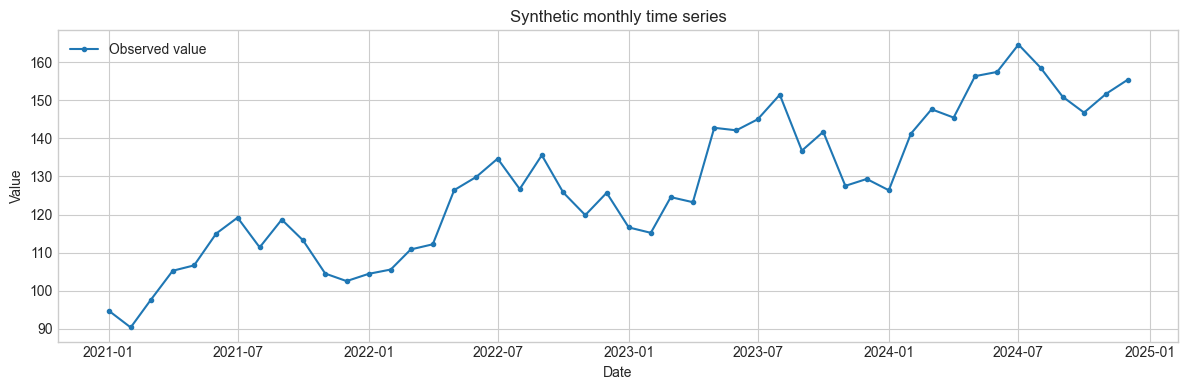

In [3]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(df.index, df['value'], marker='o', markersize=3, linewidth=1.5, label='Observed value')
ax.set(title='Synthetic monthly time series', xlabel='Date', ylabel='Value')
ax.legend()
plt.tight_layout()
plt.show()

## 4. Trend, seasonality, cycles, and noise

A useful way to describe a time series is as a combination of components:

- **Trend:** the long-term direction or gradual movement. It can rise, fall, or remain roughly flat.
- **Seasonality:** a pattern that repeats at a known, fixed frequency, such as a yearly pattern in monthly data or a weekly pattern in daily data.
- **Cyclic behavior:** rises and falls that do not have a fixed, known period. Business cycles are a common example. A cycle is not necessarily seasonal.
- **Noise (or residual variation):** movement not explained by the other components. Noise may include random variation and unmeasured influences.

Two common component models are **additive**, where components are added, and **multiplicative**, where components are multiplied. Additive components are a useful description when seasonal swings stay about the same size as the series level changes. Multiplicative components can be more appropriate when the swings grow with the level.

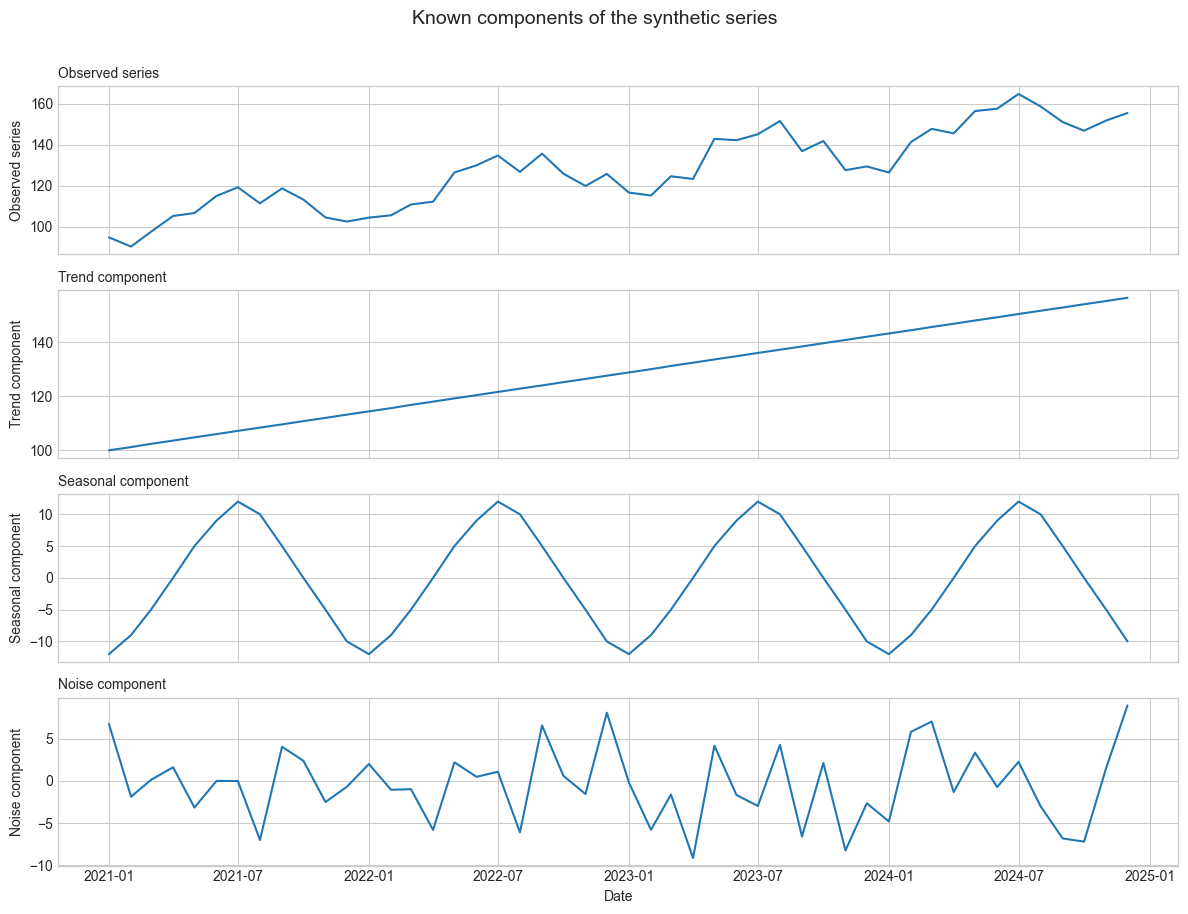

In [4]:
fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
components = [
    ('Observed series', df['value']),
    ('Trend component', df['trend']),
    ('Seasonal component', df['seasonality']),
    ('Noise component', df['noise'])
]

for ax, (title, component) in zip(axes, components):
    ax.plot(df.index, component, linewidth=1.5)
    ax.set_ylabel(title)
    ax.set_title(title, loc='left', fontsize=10)

axes[-1].set_xlabel('Date')
fig.suptitle('Known components of the synthetic series', y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

The component plot works because this synthetic dataset was constructed from known pieces. In real work, the components are not provided. Analysts estimate them using methods such as moving averages or seasonal decomposition, and the results depend on modeling choices.

## 5. Rolling statistics and smoothing

A **rolling mean** (also called a moving average) averages values in a moving window. It can make a noisy series easier to inspect, but it does not reveal the true trend perfectly and can hide short-term changes.

The **window size** is the number of observations included in each average. For monthly data, a 12-observation window spans approximately one year. Centering a window uses observations before and after each point; that is useful for descriptive plots but would use future information if applied to features in a forecasting model.

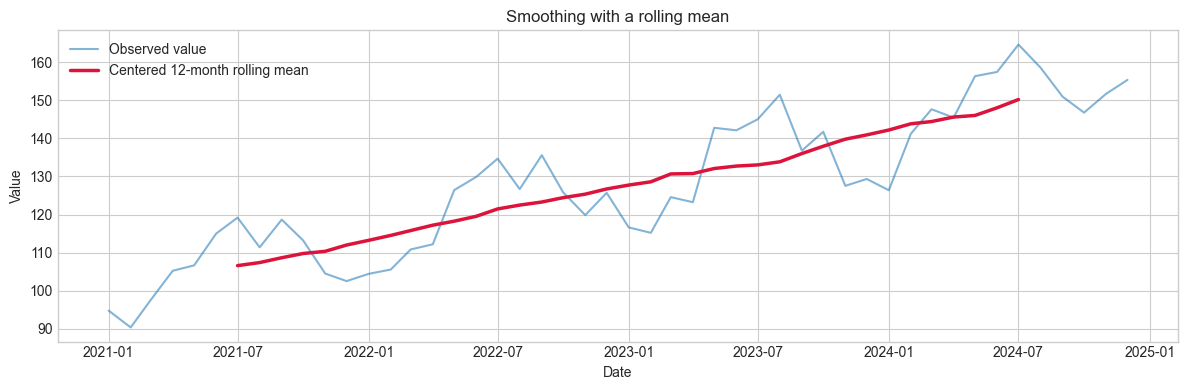

In [5]:
df['rolling_mean_12'] = df['value'].rolling(window=12, center=True).mean()
df['rolling_std_12'] = df['value'].rolling(window=12).std()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(df.index, df['value'], alpha=0.55, label='Observed value')
ax.plot(df.index, df['rolling_mean_12'], color='crimson', linewidth=2.5, label='Centered 12-month rolling mean')
ax.set(title='Smoothing with a rolling mean', xlabel='Date', ylabel='Value')
ax.legend()
plt.tight_layout()
plt.show()

## 6. Lag and autocorrelation

A **lag** is a value from an earlier time step. For monthly data, lag 1 is the previous month; lag 12 is the same month one year earlier.

**Autocorrelation** describes how strongly a series is related to its own lagged values. High autocorrelation at lag 1 means nearby observations tend to be similar. A peak at lag 12 in monthly data can indicate an annual seasonal pattern.

Autocorrelation is a relationship, not proof of cause. Trend can also create high correlations between neighboring observations, so interpret the pattern in context.

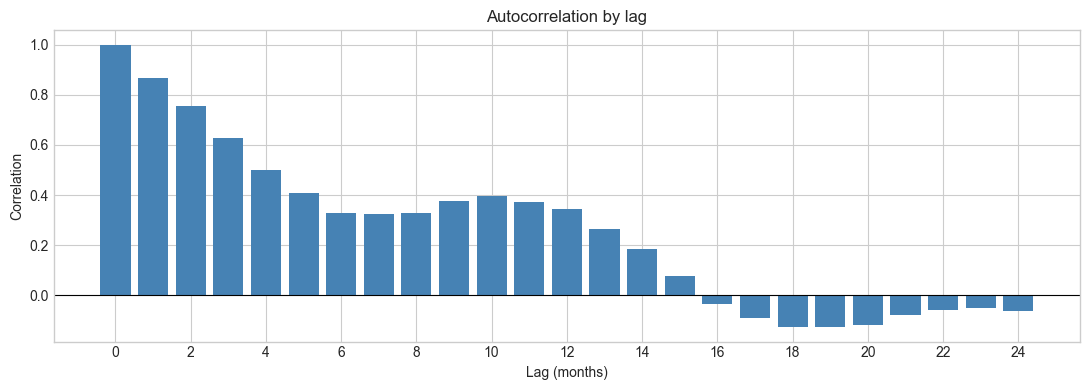

In [6]:
def autocorrelation(series, max_lag):
    """Compute correlations between a series and its lagged versions."""
    values = np.asarray(series, dtype=float)
    values = values - values.mean()
    denominator = np.dot(values, values)
    return np.array([
        np.dot(values[lag:], values[:len(values) - lag]) / denominator
        for lag in range(max_lag + 1)
    ])

max_lag = 24
acf_values = autocorrelation(df['value'], max_lag)

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(range(max_lag + 1), acf_values, color='steelblue')
ax.axhline(0, color='black', linewidth=0.8)
ax.set(title='Autocorrelation by lag', xlabel='Lag (months)', ylabel='Correlation')
ax.set_xticks(range(0, max_lag + 1, 2))
plt.tight_layout()
plt.show()

## 7. Stationarity and differencing

A series is **stationary** when its statistical behavior is broadly stable over time. In a simple explanation, this means its average level, variability, and dependence on past values do not change substantially over the period being considered.

A strong trend or changing seasonal pattern can make a series non-stationary. Some statistical forecasting methods work best when a series is stationary, though many modern methods can model trend and seasonality directly.

**Differencing** means subtracting an earlier value from the current value. First differencing is `value[t] - value[t-1]`; seasonal differencing for monthly data might subtract the value from 12 months earlier. Differencing can remove some trend or seasonality, but it can also remove useful information or over-transform the data.

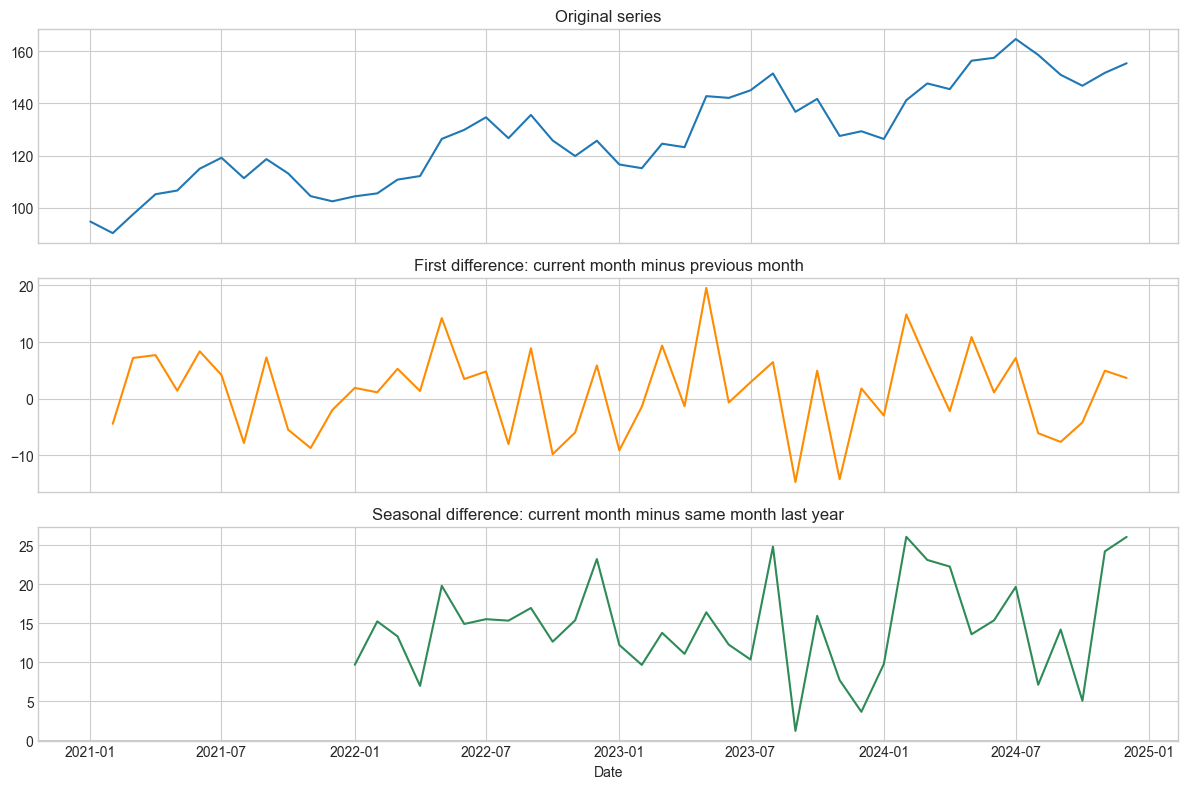

In [7]:
df['first_difference'] = df['value'].diff()
df['seasonal_difference_12'] = df['value'].diff(12)

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
axes[0].plot(df.index, df['value'])
axes[0].set_title('Original series')
axes[1].plot(df.index, df['first_difference'], color='darkorange')
axes[1].set_title('First difference: current month minus previous month')
axes[2].plot(df.index, df['seasonal_difference_12'], color='seagreen')
axes[2].set_title('Seasonal difference: current month minus same month last year')
axes[2].set_xlabel('Date')
plt.tight_layout()
plt.show()

## 8. Missing values and resampling

**Missing values** occur when an observation is absent or not recorded. Options include leaving the value missing, removing affected rows, or imputing a value. Interpolation estimates missing values between known observations, but it may be unsuitable when the series has sharp changes or when the value must be known in real time.

**Resampling** changes the time frequency, often by grouping observations into a coarser period. For example, daily data can be aggregated into monthly totals or monthly averages. Choose the aggregation according to the meaning of the measurement: sales may be summed, while temperature is often averaged.

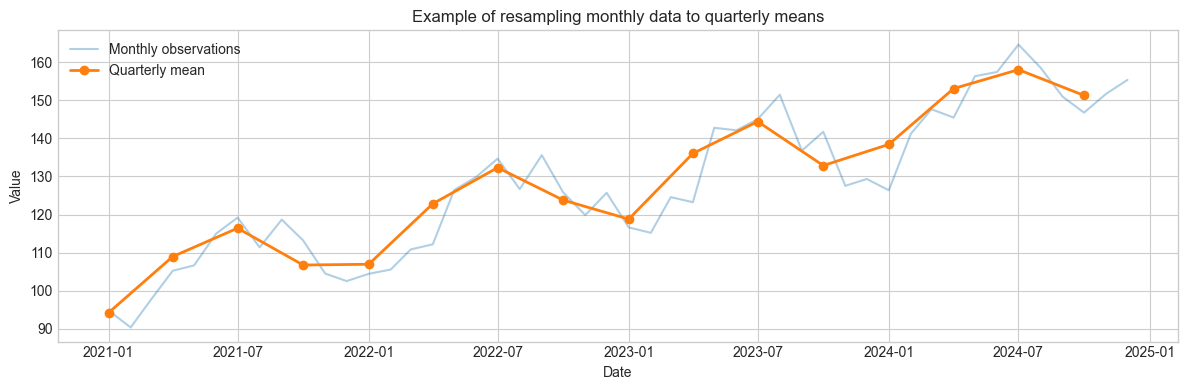

date
2021-01-01     94.209878
2021-04-01    108.960878
2021-07-01    116.416058
2021-10-01    106.738028
2022-01-01    106.934925
Freq: QS-JAN, Name: value, dtype: float64

In [8]:
# Demonstrate monthly-to-quarterly resampling.
quarterly_mean = df['value'].resample('QS').mean()
quarterly_total = df['value'].resample('QS').sum()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(df.index, df['value'], alpha=0.35, label='Monthly observations')
ax.plot(quarterly_mean.index, quarterly_mean, marker='o', linewidth=2, label='Quarterly mean')
ax.set(title='Example of resampling monthly data to quarterly means', xlabel='Date', ylabel='Value')
ax.legend()
plt.tight_layout()
plt.show()

quarterly_mean.head()

## 9. Forecasting terms and a simple baseline

A **forecast** is an estimate of future values. The **forecast horizon** is how far into the future we predict: a horizon of 3 for monthly data means three months ahead.

A **baseline model** is a simple reference that a more complex model should try to improve upon. A naive forecast repeats the latest observed value. A seasonal-naive forecast repeats the value from the same seasonal period in the past; for monthly data with yearly seasonality, that means using the value from 12 months ago.

To evaluate forecasts, keep the data in time order. A **time-based train/test split** trains on earlier observations and tests on later ones. Randomly shuffling time series observations can leak future information into training.

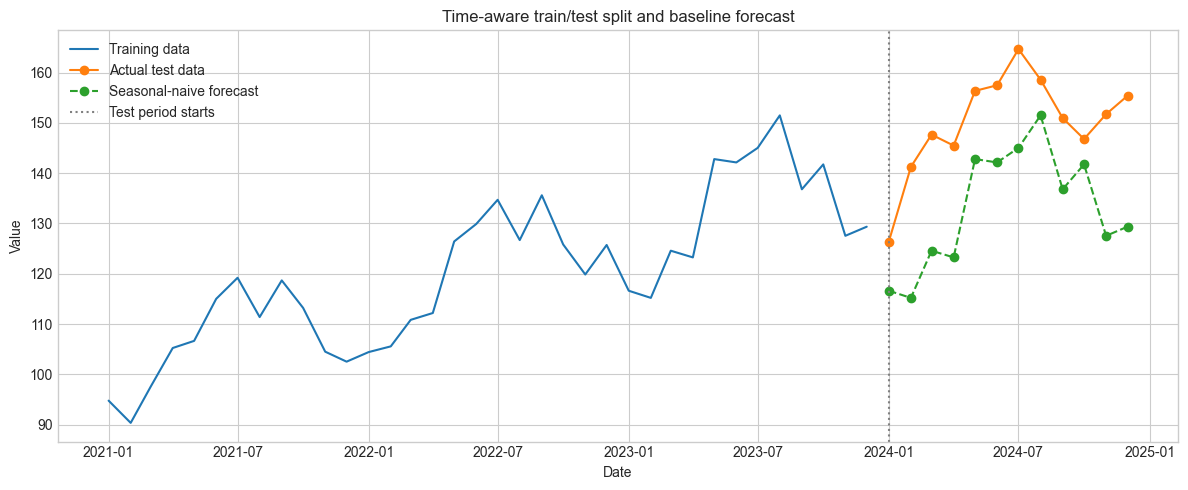

In [9]:
test_size = 12
train = df['value'].iloc[:-test_size]
test = df['value'].iloc[-test_size:]

# Seasonal-naive baseline: predict each test month using its value one year earlier.
seasonal_naive = df['value'].iloc[-2 * test_size:-test_size].to_numpy()
forecast = pd.Series(seasonal_naive, index=test.index, name='seasonal naive forecast')

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(train.index, train, label='Training data')
ax.plot(test.index, test, marker='o', label='Actual test data')
ax.plot(forecast.index, forecast, marker='o', linestyle='--', label='Seasonal-naive forecast')
ax.axvline(test.index[0], color='gray', linestyle=':', label='Test period starts')
ax.set(title='Time-aware train/test split and baseline forecast', xlabel='Date', ylabel='Value')
ax.legend()
plt.tight_layout()
plt.show()

## 10. Forecast error metrics

Forecast errors compare predictions with actual observations. Here, error is defined as `actual - forecast`.

- **MAE (Mean Absolute Error):** average absolute error. It is in the same units as the data and is easy to interpret.
- **MSE (Mean Squared Error):** average squared error. Large errors count more heavily, and the result is in squared units.
- **RMSE (Root Mean Squared Error):** square root of MSE. It is in the original units and still penalizes large errors more than MAE.
- **MAPE (Mean Absolute Percentage Error):** average absolute percentage error. It is not well-defined when actual values are zero and can behave poorly when values are close to zero.

A metric is not a complete description of forecast quality. Plot the forecast and errors, compare against a baseline, and choose metrics that match the practical cost of being wrong.

MAE:  17.19
MSE:  345.55
RMSE: 18.59
MAPE: 11.45%


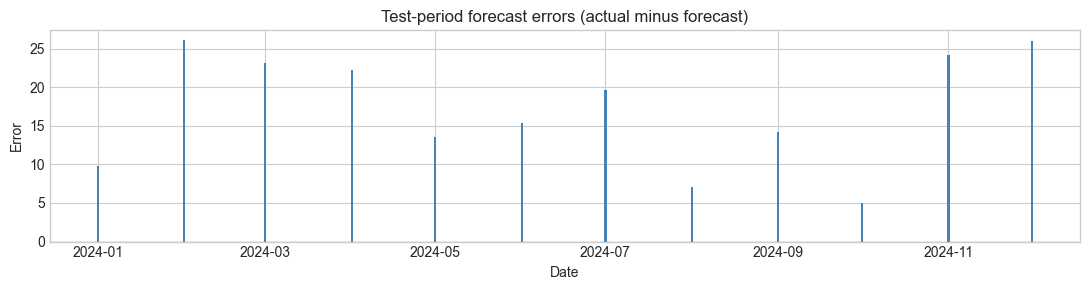

In [10]:
errors = test - forecast
mae = errors.abs().mean()
mse = (errors ** 2).mean()
rmse = np.sqrt(mse)
mape = (errors.abs() / test.abs()).mean() * 100

print(f'MAE:  {mae:.2f}')
print(f'MSE:  {mse:.2f}')
print(f'RMSE: {rmse:.2f}')
print(f'MAPE: {mape:.2f}%')

fig, ax = plt.subplots(figsize=(11, 3))
ax.bar(errors.index, errors, color=['tomato' if x < 0 else 'steelblue' for x in errors])
ax.axhline(0, color='black', linewidth=0.8)
ax.set(title='Test-period forecast errors (actual minus forecast)', xlabel='Date', ylabel='Error')
plt.tight_layout()
plt.show()

## 11. Common pitfalls

1. **Ignoring time order:** random train/test splits can let information from the future influence training.
2. **Using future information accidentally:** centered rolling windows, future-known events, or preprocessing performed on the full dataset can cause leakage.
3. **Assuming correlation means causation:** a variable that moves with the series is not necessarily causing it.
4. **Forgetting the data frequency:** lag 7 means a week only for daily data; for monthly data it means seven months.
5. **Choosing an aggregation without considering meaning:** sums, means, and last-observed values answer different questions.
6. **Treating every unusual point as an error:** unusual values can represent real events that matter to the forecast.
7. **Reporting only one metric:** a model can perform well on average and still make costly errors at important times.
8. **Extrapolating too far:** uncertainty typically increases as the forecast horizon grows.

## 12. Quick glossary

| Term | Meaning |
|---|---|
| Time series | Observations ordered by time. |
| Time index | The timestamps associated with observations. |
| Frequency | How often observations are recorded. |
| Trend | Long-term direction or movement. |
| Seasonality | Repeating pattern with a fixed, known period. |
| Cycle | Repeating rise-and-fall behavior without a fixed period. |
| Noise / residual | Variation not explained by the modeled components. |
| Lag | An earlier observation used in comparison or prediction. |
| Autocorrelation | Relationship between a series and its lagged values. |
| Stationarity | Broad stability of a series' statistical behavior over time. |
| Differencing | Subtracting a previous or seasonal value from the current value. |
| Resampling | Changing the time frequency by grouping and aggregating observations. |
| Forecast horizon | Number of future time steps being predicted. |
| Baseline | A simple model used as a comparison point. |
| Data leakage | Using information during training that would not be available at prediction time. |

## Final takeaway

Start by understanding the timestamps, frequency, and meaning of the measurement. Plot the series, identify plausible patterns, and compare forecasting methods against a simple baseline using a time-ordered evaluation. The right method depends on the data and the decision the forecast is meant to support.